# Portfolio Performance Analyzer

A 7-stock Canadian/US portfolio analyzed against the S&P/TSX 60 (XIU.TO) over 5 years.
**Everything is measured in Canadian dollars.**

This notebook is the *exploration*: each metric is computed by hand so the math is visible.
The same logic is refactored into `analyzer.py` + `main.py`; the last section checks both give identical numbers.

Each section follows the same pattern: **concept → code → what the output means → interview question.**

## Step 1 — Setup & price data

**Adjusted close prices.** When a company pays a dividend its share price drops by roughly that amount
(the cash left the company and went to shareholders). Raw prices would show that as a loss.
*Adjusted* prices rewrite history so dividends and splits are counted as return, so price change = **total return**.
This matters a lot here: RY, TD and ENB are big dividend payers.

**CAD vs USD.** AAPL and MSFT trade in USD. A Canadian investor holding them earns the stock's return
*plus* the move in USD/CAD. We convert them to CAD daily (unhedged) because (1) that is what a Canadian
investor actually experiences, and (2) the benchmark XIU.TO is in CAD, so the comparison is apples-to-apples.

**Trading calendars.** TSX and NYSE have different holidays. On a day one exchange is closed we carry
its last price forward (a closed market's price can't change).

In [1]:
import json
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

import analyzer as az   # only used for chart styling and the final cross-check

### Configuration — edit this cell to change the portfolio

In [2]:
PORTFOLIO = {
    "RY.TO":   0.20,   # Royal Bank of Canada
    "TD.TO":   0.15,   # Toronto-Dominion Bank
    "SHOP.TO": 0.15,   # Shopify
    "ENB.TO":  0.15,   # Enbridge
    "AAPL":    0.15,   # Apple (USD)
    "MSFT":    0.10,   # Microsoft (USD)
    "XIU.TO":  0.10,   # iShares S&P/TSX 60 ETF
}
BENCHMARK = "XIU.TO"
YEARS = 5
INITIAL = 10_000
FX_TICKER = "CAD=X"     # Yahoo's USD/CAD rate: how many CAD one USD buys
TRADING_DAYS = 252      # trading days in a year, used to annualize
REFRESH = False         # True = re-download instead of using the saved snapshot in data/

total_weight = sum(PORTFOLIO.values())
assert abs(total_weight - 1.0) < 1e-9, f"Weights sum to {total_weight}, not 1.0"

holdings = list(PORTFOLIO)
tickers = list(dict.fromkeys(holdings + [BENCHMARK]))  # XIU.TO is both a holding and the benchmark

In [3]:
prices_path = Path("data/prices_cad.csv")

if prices_path.exists() and not REFRESH:
    prices = pd.read_csv(prices_path, index_col=0, parse_dates=True)[tickers]
    print("Loaded saved snapshot")
else:
    raw = yf.download(tickers + [FX_TICKER], period=f"{YEARS}y", auto_adjust=True,
                      progress=False, threads=False)
    close = raw["Close"]

    # yfinance doesn't raise on a failed ticker -- it returns an empty column. Check ourselves.
    missing = [t for t in tickers + [FX_TICKER] if t not in close or close[t].isna().all()]
    if missing:
        raise RuntimeError(f"No data for {missing}. Check the symbol or re-run the cell.")

    clean = close.dropna(how="all", subset=tickers).ffill().dropna()

    # CAD price = USD price x (CAD per USD)
    usd_tickers = [t for t in tickers if not t.endswith((".TO", ".V"))]
    prices = clean[tickers].copy()
    prices[usd_tickers] = prices[usd_tickers].mul(clean[FX_TICKER], axis=0)

    Path("data").mkdir(exist_ok=True)
    prices.to_csv(prices_path)
    clean[FX_TICKER].to_csv("data/usdcad.csv")
    Path("data/risk_free.csv").unlink(missing_ok=True)
    print("Downloaded and saved a new snapshot")

print(f"{len(prices)} trading days: {prices.index[0].date()} -> {prices.index[-1].date()}")
prices.round(2).tail()

Loaded saved snapshot
1282 trading days: 2021-10-18 -> 2026-10-16


,RY.TO,TD.TO,SHOP.TO,ENB.TO,AAPL,MSFT,XIU.TO
Date,,,,,,,
2026-10-12,273.78,164.19,243.83,66.51,486.19,771.63,53.08
2026-10-13,277.25,167.83,251.04,67.55,487.34,776.06,53.76
2026-10-14,276.02,167.57,245.48,67.50,487.58,758.74,53.30
2026-10-15,279.01,170.02,252.53,66.48,486.08,766.70,54.09
2026-10-16,280.01,170.26,239.71,68.04,487.49,750.90,54.17


### How much did the currency matter?

In [4]:
fx = pd.read_csv("data/usdcad.csv", index_col=0, parse_dates=True).iloc[:, 0]
print(f"USD/CAD went from {fx.iloc[0]:.4f} to {fx.iloc[-1]:.4f} ({fx.iloc[-1] / fx.iloc[0] - 1:+.1%})")
print("So a US stock that was flat in USD would show that gain in CAD.")

USD/CAD went from 1.2374 to 1.4193 (+14.7%)
So a US stock that was flat in USD would show that gain in CAD.


> **Interview question:** *Your portfolio holds Apple and Microsoft but you benchmark against the TSX 60.
> How did you handle the currency difference, and how does it affect the risk you measured?*

## Step 2 — The risk-free rate

**Concept.** The risk-free rate is what you could earn with (essentially) zero risk. Every risky
investment should be judged by how much it beats that. For a Canadian-dollar investor the standard
choice is the **3-month Government of Canada Treasury bill** yield: short-term, backed by the federal
government, and in the same currency as our returns.

**Source.** Bank of Canada Valet API, series `TB.CDN.90D.MID` (daily mid-market yield).
Rates went from ~0.1% in 2021 to ~5% in 2023, so instead of one fixed number we use the
**actual yield on each day** — the Sharpe ratio then subtracts what cash really earned at the time.

In [5]:
rf_path = Path("data/risk_free.csv")
SERIES = "TB.CDN.90D.MID"

if rf_path.exists() and not REFRESH:
    rf_annual = pd.read_csv(rf_path, index_col=0, parse_dates=True)["rf_annual"]
else:
    url = (f"https://www.bankofcanada.ca/valet/observations/{SERIES}/json"
           f"?start_date={prices.index[0]:%Y-%m-%d}&end_date={prices.index[-1]:%Y-%m-%d}")
    with urllib.request.urlopen(url, timeout=30) as resp:
        observations = json.load(resp)["observations"]
    rf_annual = pd.Series({o["d"]: float(o[SERIES]["v"]) / 100 for o in observations
                           if o.get(SERIES, {}).get("v")}, name="rf_annual")
    rf_annual.index = pd.to_datetime(rf_annual.index)
    rf_annual.rename_axis("Date").to_csv(rf_path)

# Line the yields up with our trading days, then convert an annual yield to a daily return
rf_aligned = rf_annual.reindex(rf_annual.index.union(prices.index)).ffill().bfill().reindex(prices.index)
rf_daily = (1 + rf_aligned) ** (1 / TRADING_DAYS) - 1

print(f"3-month T-bill: start {rf_annual.iloc[0]:.2%}, end {rf_annual.iloc[-1]:.2%}, "
      f"average {rf_annual.mean():.2%}")

3-month T-bill: start 0.11%, end 2.37%, average 3.14%


> **Interview question:** *Why use the 3-month T-bill as the risk-free rate, and why not just plug in a single number like 2%?*

## Step 3 — Portfolio value and daily returns

**Concept.** A *daily return* is today's price divided by yesterday's, minus 1. It's the building block
for every other metric.

**Buy-and-hold.** We invest $10,000 on day one at the target weights (e.g. $2,000 of RY), buy whole
positions, and never trade again. Over time the weights *drift*: winners grow into a bigger share of the
portfolio. This is the realistic, zero-trading baseline. (Step 11 compares it with rebalancing.)

In [6]:
weights = pd.Series(PORTFOLIO)
shares = INITIAL * weights / prices[holdings].iloc[0]          # how many shares $ buys on day 1
port_value = (prices[holdings] * shares).sum(axis=1)            # portfolio value every day
bench_value = INITIAL * prices[BENCHMARK] / prices[BENCHMARK].iloc[0]

port_ret = port_value.pct_change().dropna()
bench_ret = bench_value.pct_change().dropna()
asset_returns = prices[holdings].pct_change().dropna()

drifted = shares * prices[holdings].iloc[-1] / port_value.iloc[-1]
pd.DataFrame({"Start weight": weights, "End weight": drifted,
              "Holding return": prices[holdings].iloc[-1] / prices[holdings].iloc[0] - 1}
             ).style.format("{:.1%}")

,Start weight,End weight,Holding return
RY.TO,20.0%,23.7%,155.3%
TD.TO,15.0%,16.8%,140.8%
SHOP.TO,15.0%,9.2%,32.1%
ENB.TO,15.0%,12.3%,76.7%
AAPL,15.0%,19.2%,175.6%
MSFT,10.0%,9.6%,105.8%
XIU.TO,10.0%,9.1%,96.0%


## Step 4 — Total return and annualized return

**Total return** = how much the investment grew over the whole period: `end / start - 1`.

**Annualized return (CAGR)** = the constant yearly rate that would produce the same total return.
It lets you compare investments held for different lengths of time.
`CAGR = (1 + total return) ^ (1 / years) - 1`.
Note it is *not* total return ÷ 5 — returns compound.

In [7]:
years = (port_value.index[-1] - port_value.index[0]).days / 365.25

def total_and_cagr(value):
    total = value.iloc[-1] / value.iloc[0] - 1
    return total, (1 + total) ** (1 / years) - 1

port_total, port_cagr = total_and_cagr(port_value)
bench_total, bench_cagr = total_and_cagr(bench_value)
print(f"Period: {years:.2f} years")
print(f"Portfolio: total {port_total:.2%}, annualized {port_cagr:.2%}  (${port_value.iloc[-1]:,.0f})")
print(f"XIU.TO:    total {bench_total:.2%}, annualized {bench_cagr:.2%}  (${bench_value.iloc[-1]:,.0f})")

Period: 4.99 years
Portfolio: total 115.01%, annualized 16.57%  ($21,501)
XIU.TO:    total 96.01%, annualized 14.43%  ($19,601)


> **Interview question:** *A fund returned 100% over 5 years. Why is its annualized return about 14.9% and not 20%?*

## Step 5 — Annualized volatility

**Concept.** Volatility is the standard deviation of returns: how much they bounce around their average.
Investors use it as the everyday measure of **risk** — a volatile portfolio can be well down exactly when you need the money.

We measure the standard deviation of *daily* returns, then scale it to a year by multiplying by √252.
Why the square root? If daily returns are independent, *variance* adds up over days, so variance scales
with 252 and standard deviation (its square root) scales with √252.

In [8]:
port_vol = port_ret.std() * np.sqrt(TRADING_DAYS)
bench_vol = bench_ret.std() * np.sqrt(TRADING_DAYS)
print(f"Portfolio annualized volatility: {port_vol:.2%}")
print(f"XIU.TO annualized volatility:    {bench_vol:.2%}")
(asset_returns.std() * np.sqrt(TRADING_DAYS)).sort_values().to_frame("Volatility").style.format("{:.1%}")

Portfolio annualized volatility: 15.06%
XIU.TO annualized volatility:    12.82%


,Volatility
XIU.TO,12.8%
RY.TO,15.2%
ENB.TO,16.0%
TD.TO,17.4%
MSFT,28.4%
AAPL,28.5%
SHOP.TO,63.9%


> **Interview question:** *Why do you multiply daily volatility by the square root of 252 rather than by 252?*

## Step 6 — Sharpe ratio

**Concept.** Return per unit of risk. *"For every unit of volatility I took on, how much did I earn above cash?"*

`Sharpe = (average return − risk-free rate) / volatility`, annualized.

Roughly: below 0.5 is weak, ~1 is good, above 2 is exceptional (and rare over long periods).
It lets you compare a calm portfolio with a wild one on equal terms.

In [9]:
def sharpe(daily_returns):
    excess = daily_returns - rf_daily.reindex(daily_returns.index)
    return excess.mean() / excess.std() * np.sqrt(TRADING_DAYS)

port_sharpe, bench_sharpe = sharpe(port_ret), sharpe(bench_ret)
print(f"Portfolio Sharpe: {port_sharpe:.2f}")
print(f"XIU.TO Sharpe:    {bench_sharpe:.2f}")

Portfolio Sharpe: 0.87
XIU.TO Sharpe:    0.86


> **Interview question:** *Your portfolio beat the benchmark by about 2 percentage points a year. Does that mean it was the better investment?*

## Step 7 — Maximum drawdown

**Concept.** The largest peak-to-trough fall: if you had bought at the worst possible high and held to
the following low, how much would you have lost? Volatility treats ups and downs the same; drawdown
measures only the pain, which is what actually makes investors panic-sell.

`drawdown(t) = value(t) / highest value so far − 1`

Portfolio max drawdown: -21.58%  (peak 2021-11-25 -> trough 2022-10-12)
XIU.TO max drawdown:    -16.36%


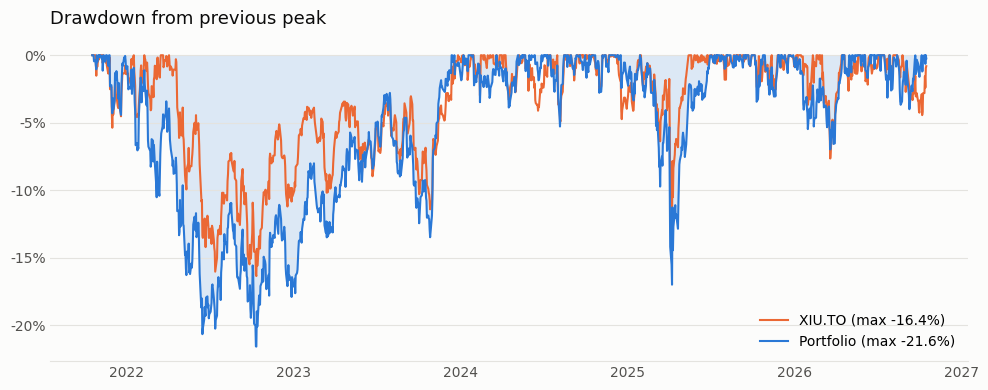

In [10]:
def drawdown(value):
    return value / value.cummax() - 1

port_dd, bench_dd = drawdown(port_value), drawdown(bench_value)
trough = port_dd.idxmin()
peak = port_value.loc[:trough].idxmax()
print(f"Portfolio max drawdown: {port_dd.min():.2%}  (peak {peak.date()} -> trough {trough.date()})")
print(f"XIU.TO max drawdown:    {bench_dd.min():.2%}")
az.plot_drawdown(port_value.rename("Portfolio"), bench_value, BENCHMARK);

> **Interview question:** *Two portfolios have the same volatility. Why might an investor still care about which has the larger max drawdown?*

## Step 8 — Beta vs the benchmark

**Concept.** Beta measures how much the portfolio moves *with the market*. Beta 1.2 means: when the TSX
moves 1%, the portfolio tends to move 1.2% the same way. It captures **market (systematic) risk** —
the kind diversification can't remove.

`beta = covariance(portfolio, benchmark) / variance(benchmark)`

Equivalently `beta = correlation × (portfolio vol / benchmark vol)`. Note XIU.TO is also a 10% holding,
which nudges correlation (and so beta) up slightly.

In [11]:
beta = port_ret.cov(bench_ret) / bench_ret.var()
corr_pb = port_ret.corr(bench_ret)
print(f"Beta: {beta:.2f}")
print(f"Check: correlation {corr_pb:.2f} x vol ratio {port_vol / bench_vol:.2f} = {corr_pb * port_vol / bench_vol:.2f}")

Beta: 1.00
Check: correlation 0.85 x vol ratio 1.17 = 1.00


> **Interview question:** *Your portfolio's beta is about 1.0 but its volatility is higher than the benchmark's. How can both be true?*

## Step 9 — Correlation matrix

**Concept.** Correlation (−1 to +1) measures how much two holdings move together day to day.
Diversification works because of *low* correlation: if two stocks don't move together, their bad days
partly cancel out, so the portfolio is less volatile than the average of its parts.

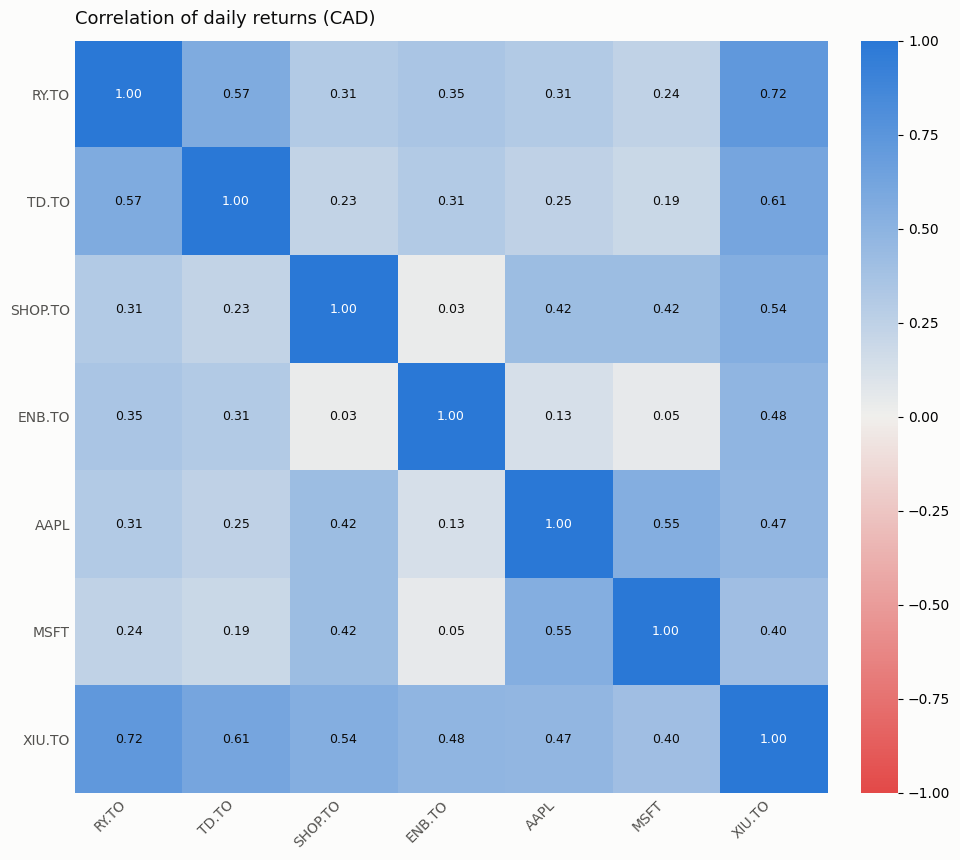

In [12]:
corr = asset_returns.corr()
az.plot_correlation(corr);

In [13]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values()
print("Least correlated pairs:\n", pairs.head(3).round(2).to_string())
print("\nMost correlated pairs:\n", pairs.tail(3).round(2).to_string())

Least correlated pairs:
 SHOP.TO  ENB.TO    0.03
ENB.TO   MSFT      0.05
         AAPL      0.13

Most correlated pairs:
 RY.TO  TD.TO     0.57
TD.TO  XIU.TO    0.61
RY.TO  XIU.TO    0.72


> **Interview question:** *Your two bank stocks have a correlation of about 0.57. What does that tell you about diversification in this portfolio?*

## Step 10 — Growth of $10,000

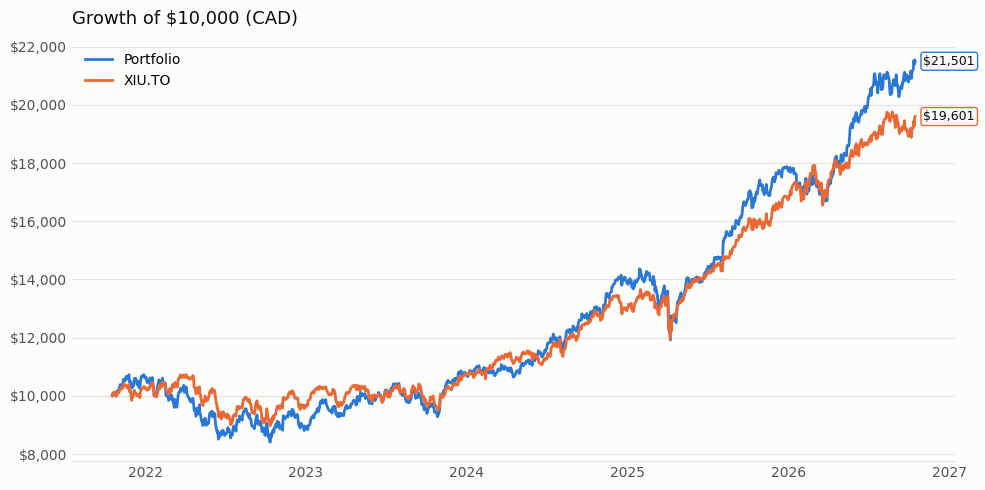

In [14]:
az.plot_growth(port_value.rename("Portfolio"), bench_value, BENCHMARK);

In [15]:
summary = pd.DataFrame({
    "Portfolio": [port_total, port_cagr, port_vol, port_sharpe, port_dd.min(), beta],
    BENCHMARK:   [bench_total, bench_cagr, bench_vol, bench_sharpe, bench_dd.min(), 1.0],
}, index=["Total return", "Annualized return", "Annualized volatility",
          "Sharpe ratio", "Max drawdown", "Beta"])
summary.style.format("{:.2%}").format("{:.2f}", subset=pd.IndexSlice[["Sharpe ratio", "Beta"], :])

,Portfolio,XIU.TO
Total return,115.01%,96.01%
Annualized return,16.57%,14.43%
Annualized volatility,15.06%,12.82%
Sharpe ratio,0.87,0.86
Max drawdown,-21.58%,-16.36%
Beta,1.00,1.00


## Stretch 1 — Monthly rebalancing vs buy-and-hold

**Concept.** Rebalancing = periodically selling what grew and buying what shrank to get back to the
target weights. It keeps your risk where you intended; it's a disciplined "sell high, buy low".
The trade-off: with buy-and-hold, winners grow into bigger positions (good if they keep winning);
rebalancing trims them.

Algorithm: hold shares; on the last trading day of each month, recompute shares so each holding is back
at its target weight of the current total. (Ignores trading costs and taxes.)

                  Total     CAGR      Vol  Sharpe    MaxDD
Buy-and-hold     115.0%    16.6%    15.1%    0.87   -21.6%
Rebalanced       137.0%    18.9%    17.6%    0.88   -27.4%

SHOP.TO: low 35.37 on 2022-10-11, start 181.43, end 239.71


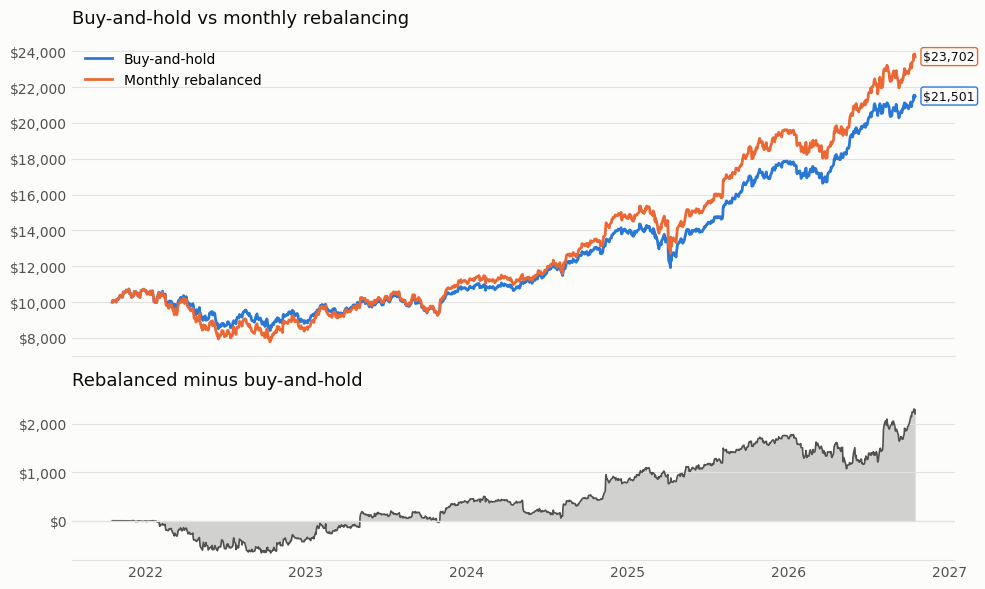

In [16]:
def rebalanced_value(prices, portfolio, freq="M", initial=INITIAL):
    w = pd.Series(portfolio)
    p = prices[w.index]
    rebalance_days = set(p.groupby(p.index.to_period(freq)).tail(1).index)
    shares = initial * w / p.iloc[0]
    values = []
    for date, row in p.iterrows():
        value = (shares * row).sum()
        values.append(value)
        if date in rebalance_days:
            shares = value * w / row      # reset to target weights
    return pd.Series(values, index=p.index)

rebal_value = rebalanced_value(prices, PORTFOLIO)
rebal_ret = rebal_value.pct_change().dropna()
rb_total, rb_cagr = total_and_cagr(rebal_value)
print(f"{'':14}{'Total':>9}{'CAGR':>9}{'Vol':>9}{'Sharpe':>8}{'MaxDD':>9}")
for name, v, r in [("Buy-and-hold", port_value, port_ret), ("Rebalanced", rebal_value, rebal_ret)]:
    t, c = total_and_cagr(v)
    print(f"{name:14}{t:>9.1%}{c:>9.1%}{r.std() * np.sqrt(TRADING_DAYS):>9.1%}"
          f"{sharpe(r):>8.2f}{drawdown(v).min():>9.1%}")
print(f"\nSHOP.TO: low {prices['SHOP.TO'].min():.2f} on {prices['SHOP.TO'].idxmin().date()}, "
      f"start {prices['SHOP.TO'].iloc[0]:.2f}, end {prices['SHOP.TO'].iloc[-1]:.2f}")
az.plot_rebalancing(port_value, rebal_value);

**Why did rebalancing win here?** Mostly Shopify. It fell ~80% in 2022, then rebounded strongly.
Buy-and-hold let SHOP shrink from 15% of the portfolio; monthly rebalancing kept *buying* it near the
bottom, then rode the recovery. The cost: deeper drawdown and higher volatility during 2022, because it
kept adding to a falling stock. This is path-dependent — in a market where one stock trends steadily
up, buy-and-hold usually wins.

> **Interview question:** *Rebalancing beat buy-and-hold in your backtest. Would you expect that to hold in general? Why or why not?*

## Stretch 2 — Efficient frontier and the max-Sharpe portfolio

**Concept (Modern Portfolio Theory, Markowitz 1952).** For every level of risk there's a mix of assets
with the highest possible expected return. The curve connecting those mixes is the *efficient frontier*.
Any portfolio below it is "inefficient": you could get more return for the same risk.
The **max-Sharpe portfolio** is the point on the frontier with the best return per unit of risk.

Inputs: the annualized mean return of each stock (`μ`) and the covariance matrix (`Σ`).
Portfolio return = `wᵀμ`, portfolio volatility = `√(wᵀΣw)`.

We (1) plot 20,000 random long-only portfolios to see the shape, then (2) use `scipy.optimize` to find
the exact max-Sharpe and minimum-volatility weights.

**Note:** `μ` here is the *arithmetic* mean of daily returns × 252, which is higher than CAGR — the gap is
roughly volatility²/2. That's why "your portfolio" shows ~19% here vs 16.6% CAGR above.

In [17]:
from scipy.optimize import minimize

mu = asset_returns.mean() * TRADING_DAYS
cov = asset_returns.cov() * TRADING_DAYS
rf_avg = rf_annual.mean()

def stats(w):
    return w @ mu.values, np.sqrt(w @ cov.values @ w)

# 1. Random portfolios: Dirichlet draws are >= 0 and sum to 1
rng = np.random.default_rng(42)
rand_w = rng.dirichlet(np.ones(len(mu)), size=20_000)
rand_ret = rand_w @ mu.values
rand_vol = np.sqrt(np.einsum("ij,jk,ik->i", rand_w, cov.values, rand_w))
rand_sharpe = (rand_ret - rf_avg) / rand_vol

# 2. Exact optimization: long-only (0..1), fully invested (sum = 1)
constraints = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
bounds = [(0, 1)] * len(mu)
x0 = np.full(len(mu), 1 / len(mu))
w_sharpe = minimize(lambda w: -(stats(w)[0] - rf_avg) / stats(w)[1], x0,
                    bounds=bounds, constraints=constraints, method="SLSQP").x
w_minvol = minimize(lambda w: stats(w)[1], x0,
                    bounds=bounds, constraints=constraints, method="SLSQP").x

rows = {}
for label, w in [("Your portfolio", weights[mu.index].values), ("Max Sharpe", w_sharpe),
                 ("Min volatility", w_minvol)]:
    r, v = stats(w)
    rows[label] = {"Return": r, "Volatility": v, "Sharpe": (r - rf_avg) / v}
pd.DataFrame(rows).T.style.format({"Return": "{:.2%}", "Volatility": "{:.2%}", "Sharpe": "{:.2f}"})

,Return,Volatility,Sharpe
Your portfolio,19.29%,17.83%,0.91
Max Sharpe,19.08%,13.10%,1.22
Min volatility,15.21%,11.71%,1.03


In [18]:
pd.DataFrame({"Current": weights[mu.index], "Max Sharpe": w_sharpe, "Min volatility": w_minvol},
             index=mu.index).style.format("{:.1%}")

,Current,Max Sharpe,Min volatility
RY.TO,20.0%,48.6%,16.1%
TD.TO,15.0%,21.6%,9.8%
SHOP.TO,15.0%,0.0%,0.0%
ENB.TO,15.0%,12.5%,29.8%
AAPL,15.0%,13.5%,0.0%
MSFT,10.0%,3.7%,6.2%
XIU.TO,10.0%,0.0%,38.0%


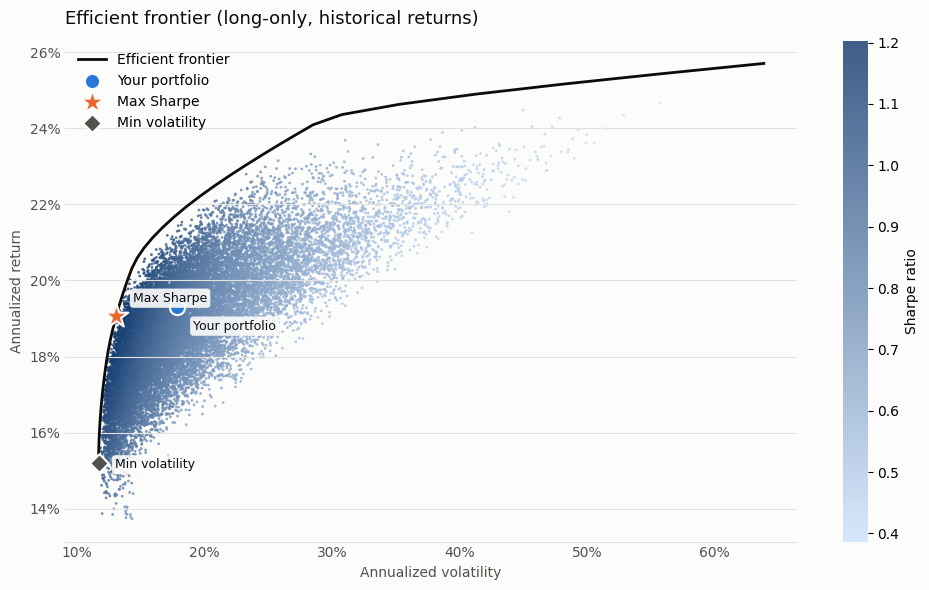

In [19]:
f_vols, f_rets = az.efficient_frontier(mu, cov)
points = {k: (v["Volatility"], v["Return"]) for k, v in rows.items()}
az.plot_frontier(rand_vol, rand_ret, rand_sharpe, f_vols, f_rets, points);

**Big caveat — say this in interviews.** The max-Sharpe weights are fitted to *the past 5 years*.
They pile into whatever happened to do best (here RY, TD), and small changes in the expected-return
inputs swing the weights a lot. Out of sample, "optimal" portfolios often disappoint. Treat it as
"what would have been best", not a forecast.

> **Interview question:** *Your optimizer says to put about half the portfolio in RBC. Would you actually do that? What are the weaknesses of mean-variance optimization?*

## Stretch 3 — Monte Carlo simulation of 1-year outcomes

**Concept.** Instead of one forecast, simulate thousands of possible next years and look at the
*distribution* of outcomes: the median, a bad case (5th percentile), a good case (95th).

**Method: bootstrap.** Build each simulated year by drawing 252 random *historical days* (with replacement)
and compounding the portfolio's return on those days. Drawing whole days keeps the real co-movement
between stocks and the real fat tails (big crash days), with no assumption that returns are normally distributed.

**Value at Risk (VaR):** the 95% 1-year VaR is the loss you'd exceed only 5% of the time
(= start value − 5th percentile).

Median outcome:      $11,997
5th-95th percentile: $8,860 to $15,953
Probability of loss: 15.8%
95% 1-year VaR:      $1,140


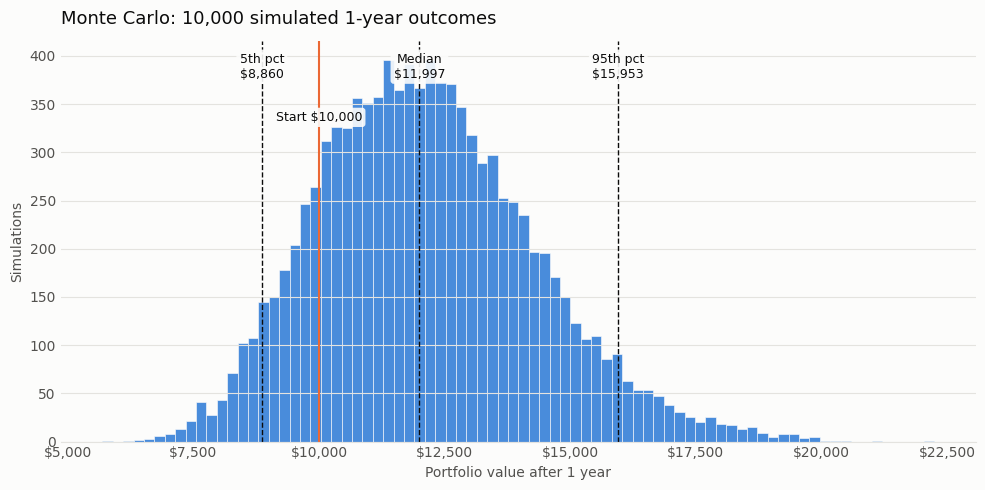

In [20]:
N_SIMS, DAYS = 10_000, 252
port_daily = (asset_returns[holdings] @ weights[holdings]).values   # fixed-weight daily return
rng = np.random.default_rng(42)
picks = rng.integers(0, len(port_daily), size=(N_SIMS, DAYS))       # random day numbers
paths = INITIAL * np.cumprod(1 + port_daily[picks], axis=1)          # value along each path
ending = paths[:, -1]

p5, p25, p50, p75, p95 = np.percentile(ending, [5, 25, 50, 75, 95])
print(f"Median outcome:      ${p50:,.0f}")
print(f"5th-95th percentile: ${p5:,.0f} to ${p95:,.0f}")
print(f"Probability of loss: {(ending < INITIAL).mean():.1%}")
print(f"95% 1-year VaR:      ${INITIAL - p5:,.0f}")
az.plot_monte_carlo(paths, INITIAL);

**Caveat.** A bootstrap assumes the next year looks like a random mix of the last five. Those five years
were unusually strong (and included a currency tailwind), so the median is probably optimistic.

> **Interview question:** *What are the limitations of your Monte Carlo simulation, and how would you make it more realistic?*

## Refactor check — notebook vs `analyzer.py`

The production code lives in `analyzer.py` (functions) and `main.py` (runs everything, saves charts and
`results/summary.json`). This cell proves the refactor didn't change any numbers.

In [21]:
import config

m = az.compute_metrics(port_value, bench_value, rf_daily)
mod_paths = az.monte_carlo(asset_returns, config.PORTFOLIO, N_SIMS, DAYS, INITIAL, seed=42)
checks = {
    "Total return": (port_total, m["Total return"]),
    "Annualized return": (port_cagr, m["Annualized return"]),
    "Volatility": (port_vol, m["Annualized volatility"]),
    "Sharpe": (port_sharpe, m["Sharpe ratio"]),
    "Max drawdown": (port_dd.min(), m["Max drawdown"]),
    "Beta": (beta, m["Beta"]),
    "Rebalanced end value": (rebal_value.iloc[-1], az.rebalanced_value(prices, PORTFOLIO).iloc[-1]),
    "Max-Sharpe weights": (w_sharpe, az.max_sharpe_weights(mu, cov, rf_avg).values),
    "Monte Carlo median": (p50, np.median(mod_paths[:, -1])),
}
assert config.PORTFOLIO == PORTFOLIO, "config.py and this notebook use different portfolios"
for name, (nb, mod) in checks.items():
    assert np.allclose(nb, mod, atol=1e-3), name
print("All", len(checks), "checks match.")

All 9 checks match.
